---
title: | 
    Creating custom distribution in `PyMC`
author: Sheng Long 
---

The [old tutorial](https://www.pymc.io/projects/examples/en/stable/howto/custom_distribution.html) in the official documentation is meant for PyMC3. The latest version of PyMC uses a different way, but we will nevertheless use the Generalized Poisson distribution as an example. 

The Generalized Poisson distribution, aka the Lagrangian Poisson distribution, models count data, and is flexible enough to handle both overdispersion and underdispersion. It has the following PMF: 

$$
p(Y = y | \theta, \lambda) = \frac{\theta(\theta+\lambda y)^{y-1}e^{-\theta-\lambda y}}{y!}
$$
where $\theta > 0$ and $\max(-1, -\frac{\theta}{4}) \leq \lambda \leq 1$

In [4]:
import pymc as pm 
from pymc.distributions.dist_math import factln
import arviz as az 
import arviz_plots as azp
import numpy as np 


We will first need to define the log of the probability function: 
$$
\log(f(y|\theta, \lambda)) = \log(\theta) + (y-1) \log(\theta + \lambda y) - (\theta + \lambda y) - \log(y!)
$$

In [5]:
def gen_possion_logp(theta, lam, value):
    theta_lam_value = theta + lam * value 
    log_prob = pm.math.log(theta) + (value - 1) * pm.math.log(theta_lam_value) - theta_lam_value - factln(value)

    if theta_lam_value <= 0:
        log_prob = -np.inf

    return log_prob 

Then define a random sample generator: 

In [7]:
def genpoisson_rvs(theta, lam, size=None):
    if size is not None:
        assert size == theta.shape
    else:
        size = theta.shape
    lam = lam[0]
    omega = np.exp(-lam)
    X = np.full(size, 0)
    S = np.exp(-theta)
    P = np.copy(S)
    for i in range(size[0]):
        U = np.random.uniform()
        while U > S[i]:
            X[i] += 1
            C = theta[i] - lam + lam * X[i]
            P[i] = omega * C * (1 + lam / C) ** (X[i] - 1) * P[i] / X[i]
            S[i] += P[i]
    return X

## Trying with `pymc.DensityDist`

[source](https://www.pymc.io/projects/docs/en/v4.4.0/api/distributions/generated/pymc.DensityDist.html)

In [8]:
def logp(value, mu):
    return -(value - mu)**2

with pm.Model():
    mu = pm.Normal('mu',0,1)
    pm.DensityDist(
        'density_dist',
        mu,
        logp=logp,
        observed=np.random.randn(100),
    )
    idata = pm.sample(100)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu]


                                                                               
                              Step      Grad      Sampli…                      
  Progre…   Draws   Diverg…   size      evals     Speed     Elapsed   Remain…  
 ───────────────────────────────────────────────────────────────────────────── 
  -------   0       0         0.000     0         0.00      0:00:00   -:--:--  
                                                  draws/s                      
  -------   0       0         0.000     0         0.00      0:00:00   -:--:--  
                                                  draws/s                      
  -------   0       0         0.000     0         0.00      0:00:00   -:--:--  
                                                  draws/s                      
  -------   0       0         0.000     0         0.00      0:00:00   -:--:--  
                                                  draws/s                      
                                        

Sampling 4 chains for 1_000 tune and 100 draw iterations (4_000 + 400 draws total) took 16 seconds.
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


array([<Axes: title={'center': '94.0% HDI'}>], dtype=object)

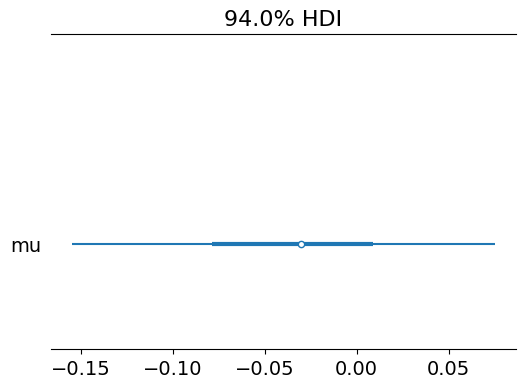

In [14]:
az.plot_forest(idata, combined=True)

In [16]:
def logp(value, mu):
    return -(value - mu)**2

def random(mu, rng=None, size=None):
    return rng.normal(loc=mu, scale=1, size=size)

with pm.Model():
    mu = pm.Normal('mu', 0 , 1)
    dens = pm.DensityDist(
        'density_dist',
        mu,
        logp=logp,
        random=random,
        observed=np.random.randn(100, 3),
        size=(100, 3),
    )
    prior = pm.sample_prior_predictive(10).prior_predictive['density_dist']
# assert prior.shape == (1, 10, 100, 3)

Sampling: [density_dist, mu]


## Trying with `pymc.CustomDist`

[source](https://www.pymc.io/projects/docs/en/v5.9.2/api/distributions/generated/pymc.CustomDist.html)

In [ ]:
from pytensor.tensor import TensorVariable
from typing import Optional, Tuple

def logp(value: TensorVariable, mu: TensorVariable) -> TensorVariable:
    return -(value - mu)**2

def random(
    mu: np.ndarray | float,
    rng: Optional[np.random.Generator] = None,
    size : Optional[Tuple[int]]=None,
) -> np.ndarray | float :
    return rng.normal(loc=mu, scale=1, size=size)

with pm.Model():
    mu = pm.Normal('mu', 0 , 1)
    pm.CustomDist(
        'custom_dist',
        mu,
        logp=logp,
        random=random,
        observed=np.random.randn(100, 3),
        size=(100, 3),
    )
    prior = pm.sample_prior_predictive(10)

Sampling: [custom_dist, mu]
